# 13 · The verdict: are today's meat prices justified?

**Milestone 4, item 4.5** (with items 4.1 and 4.2 folded in) · see `docs/MILESTONES.md`

## What we're looking for

This is the question the project set out to answer. "Justified" can mean many things, so
we use three tests anyone can check:

1. **Inflation (item 4.1):** has the meat risen faster than prices in general? If it
   hasn't, it isn't really more expensive than it was.
2. **Who gets the dollar (item 4.2):** of each dollar a shopper pays, how much goes to
   the rancher or farmer, the packer and the store, after inflation? If the middle took a
   much bigger cut while farmers got less, that points away from "justified".
3. **Supply:** is the price in line with what the cattle supply predicts? Notebook 12
   found a 1% smaller herd goes with about a 1.8% higher real beef price. Here we ask
   whether **today's** beef price fits that relationship. This test is beef only; pork
   and chicken don't have a comparable supply series in this project, and they pass test
   1 anyway.

Then one plain-language verdict per meat.

**Sections**
1. Setup
2. Test 1: meat vs. inflation
3. Test 2: who gets each dollar
4. Test 3: does supply explain today's beef price?
5. The verdict
6. What's next

## Reading guide (no statistics background needed)

**What this notebook does:** it answers the project's main question, *are today's meat
prices justified?*, with three plain tests for each meat.

**Words you'll see:**
- **Real / after inflation / today's dollars:** prices adjusted so every year is
  measured in September 2026 dollars, making years fair to compare.
- **2015–2019 average:** a "before the run-up" baseline.
- **Price spread:** USDA's measure of how a pound of meat's price splits between the
  rancher or farmer, the meatpacker and the store. A spread pays for costs as well as
  profit, so a bigger spread isn't proof of overcharging.
- **Out-of-sample test:** the herd-to-price pattern is learned from 2015–2025 and then
  used to predict 2026, a year it hasn't seen. That's a fairer test than checking a
  pattern against the data it came from.
- **95% prediction range:** where the 2026 price should land 19 times out of 20 if the
  usual pattern holds. Above it means "higher than the cattle shortage explains".

**If you only read one part:** section 5, *The verdict*, and section 6, *What we found*.

**Want the whole project in plain language?** See *Findings and methods explained*: `docs/FINDINGS.md` in the repo, or **Docs** in the bar at the top of the project site.

## 1 · Setup

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from dotenv import find_dotenv

warnings.filterwarnings("ignore")
env_path = find_dotenv()
PROJECT_ROOT = Path(env_path).parent if env_path else Path.cwd().parent
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "master_monthly.csv", parse_dates=["date"]).set_index("date")

MEATS = {"beef": "Ground beef", "pork": "Pork chops", "chicken": "Chicken breast"}
COLORS = {"beef": "#9A3B2E", "pork": "#2F6690", "chicken": "#C08A1E"}
STAGE_COLORS = {"rancher / farmer": "#5B3A1E", "packer / processor": "#7A4E9C", "store": "#3C8D5A"}
BASE_MONTH = df["cpi_all_items"].last_valid_index()
LATEST_YEAR = BASE_MONTH.year
# Turns a price at the time into BASE_MONTH dollars (same method as the *_real columns, D27)
TO_TODAY = df.loc[BASE_MONTH, "cpi_all_items"] / df["cpi_all_items"]


def style(ax):
    ax.grid(alpha=0.3)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)


print(f"Prices through {BASE_MONTH:%B %Y}; real values in {BASE_MONTH:%B %Y} dollars. "
      f"{LATEST_YEAR} figures are averages of the months so far.")

Prices through September 2026; real values in September 2026 dollars. 2026 figures are averages of the months so far.


## 2 · Test 1: meat vs. inflation (item 4.1)

**What we're looking for:** how much each meat's price has changed since 2015, before and
after removing general inflation, and how today's real price compares with the
**2015–2019 average**, a "before the run-up" baseline.

In [2]:
rows = {}
for meat, name in MEATS.items():
    nominal, real = df[f"{meat}_price"], df[f"{meat}_price_real"]
    rows[name] = {
        "price now ($/lb)": nominal.loc[BASE_MONTH],
        "change since 2015 (%)": (nominal.loc[BASE_MONTH] / nominal.loc["2015"].mean() - 1) * 100,
        "real change since 2015 (%)": (real.loc[BASE_MONTH] / real.loc["2015"].mean() - 1) * 100,
        "real price vs 2015-2019 average (%)": (real.loc[BASE_MONTH] / real.loc["2015":"2019"].mean() - 1) * 100,
    }
cpi_change = (df.loc[BASE_MONTH, "cpi_all_items"] / df.loc["2015", "cpi_all_items"].mean() - 1) * 100
test1 = pd.DataFrame(rows).T.round(1)
print(f"Prices in general (CPI) since 2015: +{cpi_change:.0f}%")
test1

Prices in general (CPI) since 2015: +42%


,price now ($/lb),change since 2015 (%),real change since 2015 (%),real price vs 2015-2019 average (%)
Ground beef,6.8,63.0,14.7,29.6
Pork chops,4.2,9.2,-23.2,-12.6
Chicken breast,4.2,23.3,-13.3,-4.1


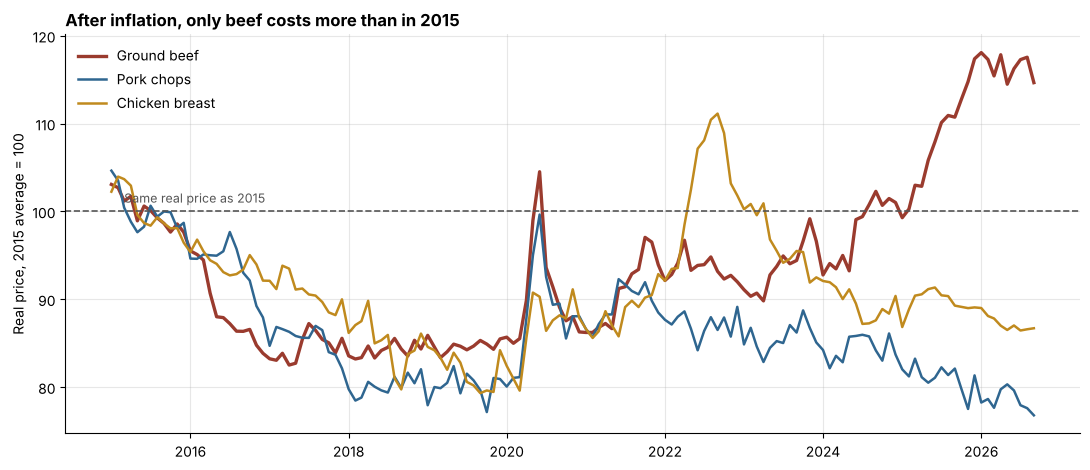

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.8))
real = df.loc["2015":]
for meat, name in MEATS.items():
    s = real[f"{meat}_price_real"] / real.loc["2015", f"{meat}_price_real"].mean() * 100
    ax.plot(s.index, s, color=COLORS[meat], linewidth=2.4 if meat == "beef" else 1.8, label=name)
ax.axhline(100, color="#555555", linewidth=1.2, linestyle="--")
ax.annotate("Same real price as 2015", (real.index[2], 101), fontsize=9, color="#555555")
ax.set_ylabel("Real price, 2015 average = 100")
ax.set_title("After inflation, only beef costs more than in 2015", loc="left", fontweight="bold")
ax.legend(frameon=False)
style(ax)
fig.tight_layout()
plt.show()

### How to read it
**Table:**
- **change since 2015:** the shelf price now compared with the 2015 average.
- **real change since 2015:** the same comparison after removing inflation.
- **real price vs 2015–2019 average:** compares today with the whole pre-pandemic
  period, not just one year.

**Chart:** each meat's inflation-adjusted price, with its 2015 average set to 100. Above
the dashed line means more expensive than in 2015 after inflation; below means cheaper.

### What it means
**Only beef costs more than it used to, after inflation.**
- **Ground beef** is 15% above its 2015 real price and **30% above its 2015–2019 average**.
- **Pork chops** are 23% cheaper in real terms than in 2015, and 13% below the pre-pandemic average.
- **Chicken breast** is 13% cheaper than in 2015, and 4% below the pre-pandemic average.

Pork and chicken pass this test easily. Their shelf prices rose, but by less than prices in general, so they take a smaller share of a shopper's money than they did before the pandemic. Beef is the only one that needs explaining.

## 3 · Test 2: who gets each dollar (item 4.2)

**What we're looking for:** USDA's price spreads follow a pound of meat through three
stages. We split the retail price into three parts, all in today's dollars:
- **Rancher / farmer:** what the farm is paid.
- **Packer / processor:** the farm-to-wholesale spread, what the meatpacker keeps to
  cover slaughter, processing and profit.
- **Store:** the wholesale-to-retail spread, which covers the store's costs (labor,
  rent, energy, waste) and profit.

The key question: **since the run-up began in 2019, which part grew?**

Two cautions:
- A spread is **not profit**. It also pays for costs, which rose with wages and energy.
- USDA's beef figures are for **all fresh beef**, not just ground beef, so the totals
  differ from the BLS prices in test 1. Chicken has only two stages, wholesale (which
  includes the farm) and store.

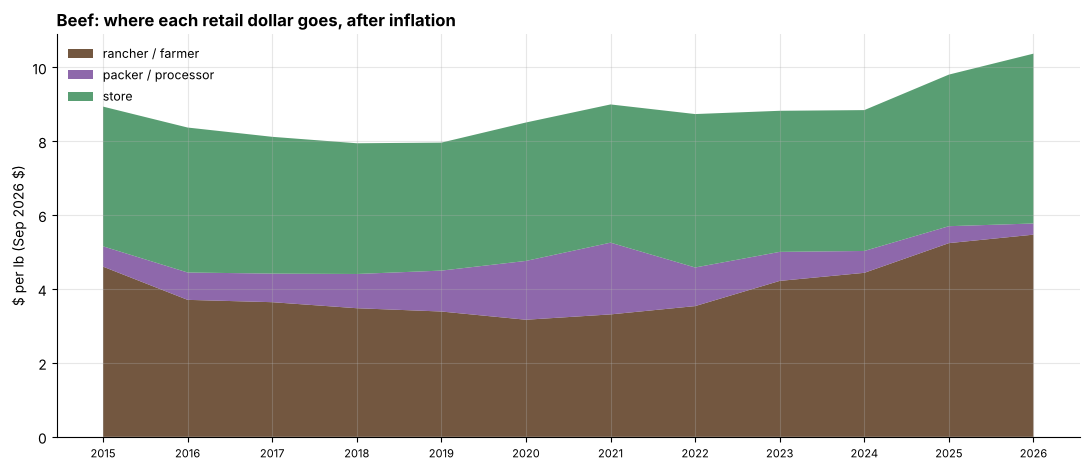

2019 ($/lb)  2025 ($/lb)  2026 ($/lb)  \
meat    stage                                                              
beef    rancher / farmer                  3.39         5.24         5.47   
        packer / processor                1.11         0.46         0.30   
        store                             3.46         4.10         4.60   
pork    rancher / farmer                  1.09         1.24         1.16   
        packer / processor                0.82         0.81         0.59   
        store                             3.15         3.12         3.23   
chicken farm + packer (wholesale)         1.01         1.11         0.95   
        store                             1.46         1.46         1.46   

                                   change 2019-2026 ($/lb)  \
meat    stage                                                
beef    rancher / farmer                              2.08   
        packer / processor                           -0.81   
        store                                         1.13   
pork    rancher / farmer                              0.07   
        packer / processor                           -0.23   
        store                                         0.08   
chicken farm + packer (wholesale)                    -0.06   
        store                                        -0.00   

                                   share of the total change (%)  
meat    stage                                                     
beef    rancher / farmer                                   86.38  
        packer / processor                                -33.42  
        store                                              47.04  
pork    rancher / farmer                                     NaN  
        packer / processor                                   NaN  
        store                                                NaN  
chicken farm + packer (wholesale)                            NaN  
        store                                                NaN

In [4]:
PARTS = {
    "beef": {"rancher / farmer": "net_farm", "packer / processor": "spread_farm_to_wholesale",
             "store": "spread_wholesale_to_retail"},
    "pork": {"rancher / farmer": "net_farm", "packer / processor": "spread_farm_to_wholesale",
             "store": "spread_wholesale_to_retail"},
    "chicken": {"farm + packer (wholesale)": "wholesale", "store": "spread_wholesale_to_retail"},
}


def dollars_by_stage(meat):
    """Yearly average of each stage's part of the retail price, in dollars per lb (BASE_MONTH dollars)."""
    out = {stage: (df[f"ers_{meat}_{col}"] * TO_TODAY / 100).groupby(df.index.year).mean()  # ERS is in cents
           for stage, col in PARTS[meat].items()}
    return pd.DataFrame(out).loc[2015:]


beef_parts = dollars_by_stage("beef")
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.stackplot(beef_parts.index, beef_parts.T.values, labels=beef_parts.columns,
             colors=[STAGE_COLORS[c] for c in beef_parts.columns], alpha=0.85)
ax.set_ylabel(f"$ per lb ({BASE_MONTH:%b %Y} $)".replace("$", r"\$"))
ax.set_title("Beef: where each retail dollar goes, after inflation", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.set_xticks(beef_parts.index)
ax.tick_params(axis="x", labelsize=8)
style(ax)
fig.tight_layout()
plt.show()

summary = []
for meat in MEATS:
    parts = dollars_by_stage(meat)
    rise = parts.loc[LATEST_YEAR] - parts.loc[2019]
    for stage in parts.columns:
        summary.append({"meat": meat, "stage": stage,
                        "2019 ($/lb)": parts.loc[2019, stage], f"{LATEST_YEAR - 1} ($/lb)": parts.loc[LATEST_YEAR - 1, stage],
                        f"{LATEST_YEAR} ($/lb)": parts.loc[LATEST_YEAR, stage],
                        f"change 2019-{LATEST_YEAR} ($/lb)": rise[stage],
                        "share of the total change (%)": rise[stage] / rise.sum() * 100 if abs(rise.sum()) >= 0.25 else np.nan})  # blank when the total barely moved
test2 = pd.DataFrame(summary).set_index(["meat", "stage"]).round(2)
test2

### How to read it
**Chart:** the height of the stack is the real retail price of a pound of fresh beef
each year. The three bands show how it splits: rancher at the bottom, packer in the
middle, store on top.

**Table:** each stage's part of the price in 2019, last year and this year (in today's
dollars), and how much it changed since 2019. **share of the total change** shows which
stage the rise went to; a negative share means that stage got *less*. For pork and
chicken the total barely changed, so shares aren't meaningful and are left blank.

### What it means
**Beef: the rise went mostly to ranchers.** Since 2019 the real retail price of a pound of fresh beef rose about **$2.40**:
- **Ranchers got $2.08 of it (86%).** That's what a cattle shortage looks like: scarce cattle command a higher price.
- **Packers got $0.81 *less* (−33%).** Their part fell from $1.11 to $0.30 a pound. They are paying record prices for cattle and can't pass all of it on, so they're being squeezed.
- **Stores got $1.13 more (47%).** Most of that came in 2026 alone: the store part rose $0.50 from 2025 to 2026, while the rancher's rose only $0.23.

So through 2025, almost the whole rise went to ranchers. In 2026, the extra went mainly to stores. A store spread pays for labor, rent, energy and waste as well as profit, so this data can't say how much of the 2026 jump is higher costs and how much is wider margins.

**Pork and chicken:** almost nothing changed. Each stage's part is within a few cents of 2019 in real terms, except the pork packer's, which shrank.

## 4 · Test 3: does supply explain today's beef price?

**What we're looking for:** notebook 12 fitted the real beef price to the herd. Here we
fit the same relationship using **2015–2025 only**, then ask what it predicts for 2026,
a year the fit hasn't seen. If 2026's actual price sits inside the **95% prediction
range**, the herd explains today's price. If it's above, beef is running ahead of what
supply alone can explain.

We use the **average price over 2026 so far**, because the herd is counted once a year
and single months jump around.

In [5]:
by_year = pd.DataFrame({
    "herd_jan1": df["herd_beef_cows_jan1"].groupby(df.index.year).first(),
    "beef_price_real": df["beef_price_real"].groupby(df.index.year).mean(),
}).dropna()
train = by_year.loc[:LATEST_YEAR - 1]
fit = sm.OLS(np.log(train["beef_price_real"]), sm.add_constant(np.log(train["herd_jan1"]))).fit()
new = sm.add_constant(np.log(by_year["herd_jan1"]), has_constant="add").loc[[LATEST_YEAR]]
pred = np.exp(fit.get_prediction(new).summary_frame(alpha=0.05).iloc[0])
actual = by_year.loc[LATEST_YEAR, "beef_price_real"]
gap = (actual / pred["mean"] - 1) * 100

print(f"Fitted on {train.index.min()}-{train.index.max()}: elasticity {fit.params.iloc[1]:.2f}")
print(f"{LATEST_YEAR} herd: {by_year.loc[LATEST_YEAR, 'herd_jan1'] / 1e6:.2f} million beef cows")
print(f"Predicted real price: ${pred['mean']:.2f}/lb (95% range ${pred['obs_ci_lower']:.2f} to ${pred['obs_ci_upper']:.2f})")
print(f"Actual {LATEST_YEAR} average: ${actual:.2f}/lb, {gap:+.0f}% vs predicted")

Fitted on 2015-2025: elasticity -1.50
2026 herd: 27.61 million beef cows
Predicted real price: $6.20/lb (95% range $5.59 to $6.87)
Actual 2026 average: $6.90/lb, +11% vs predicted


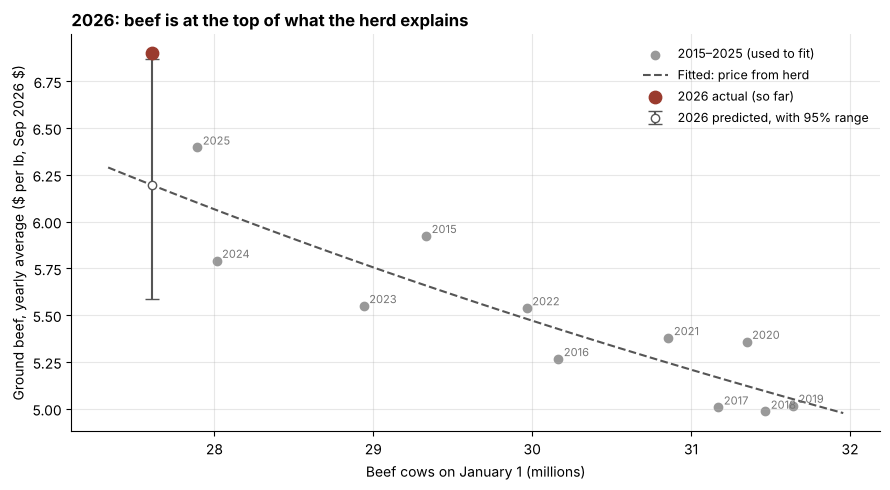

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(train["herd_jan1"] / 1e6, train["beef_price_real"], color="#999999", s=36, label="2015–2025 (used to fit)")
for yr, r in train.iterrows():
    ax.annotate(str(yr), (r["herd_jan1"] / 1e6, r["beef_price_real"]), xytext=(4, 2), textcoords="offset points",
                fontsize=8, color="#777777")
hs = np.linspace(by_year["herd_jan1"].min() * 0.99, by_year["herd_jan1"].max() * 1.01, 50)
ax.plot(hs / 1e6, np.exp(fit.params.iloc[0] + fit.params.iloc[1] * np.log(hs)), color="#555555", linestyle="--",
        label="Fitted: price from herd")
h26 = by_year.loc[LATEST_YEAR, "herd_jan1"] / 1e6
ax.errorbar(h26, pred["mean"], yerr=[[pred["mean"] - pred["obs_ci_lower"]], [pred["obs_ci_upper"] - pred["mean"]]],
            fmt="o", color="#555555", markerfacecolor="white", capsize=5, label=f"{LATEST_YEAR} predicted, with 95% range")
ax.scatter(h26, actual, color=COLORS["beef"], s=80, zorder=4, label=f"{LATEST_YEAR} actual (so far)")
ax.set_xlabel("Beef cows on January 1 (millions)")
ax.set_ylabel(f"Ground beef, yearly average ($ per lb, {BASE_MONTH:%b %Y} $)".replace("$", r"\$"))
ax.set_title(f"{LATEST_YEAR}: beef is at the top of what the herd explains", loc="left", fontweight="bold")
ax.legend(frameon=False, fontsize=9)
style(ax)
fig.tight_layout()
plt.show()

### How to read it
Gray dots are the years used to fit the relationship, and the dashed curve is the fit.
The hollow dot with whiskers is the price the fit predicts for 2026 from 2026's herd,
with its 95% range. The red dot is 2026's actual average so far. Red inside the
whiskers means the herd explains it; above them means beef is costing more than the
herd alone accounts for.

### What it means
Fitted on 2015–2025 only, the herd predicts a 2026 real price of about **$6.20 a pound**, with a 95% range of $5.59 to $6.87. The actual 2026 average so far is **$6.90**: **11% above the prediction**, and just above the top of the range. (The fitted elasticity here is −1.5. Notebook 12's −1.8 included 2026 itself.)

So **through 2025, the herd explains beef's price; in 2026, beef is running ahead of it.** Test 2 shows where that extra went: mostly into the store's part of the price.

This data can't say why. Possible reasons are:
- higher store costs
- stores pricing ahead of an expected further tightening (notebook 12 found ranchers are holding on to their cows, which keeps beef scarce)
- wider margins
- imports and tariffs, which aren't in this data

With 11 years behind the fit and a partial 2026, this is a signal to watch, not a firm conclusion.

## 5 · The verdict

**What we're looking for:** one plain-language answer per meat, based on the three tests.

In [7]:
verdict = pd.DataFrame({
    "1. vs inflation": {
        "Ground beef": f"{test1.loc['Ground beef', 'real change since 2015 (%)']:+.0f}% real since 2015",
        "Pork chops": f"{test1.loc['Pork chops', 'real change since 2015 (%)']:+.0f}% real since 2015",
        "Chicken breast": f"{test1.loc['Chicken breast', 'real change since 2015 (%)']:+.0f}% real since 2015"},
    "2. who got the rise since 2019": {
        "Ground beef": "mostly ranchers; store margin up; packers down",
        "Pork chops": "little change; packers down",
        "Chicken breast": "little change"},
    "3. explained by supply?": {
        "Ground beef": f"yes through {LATEST_YEAR - 1}; {LATEST_YEAR} {gap:+.0f}% above the herd's prediction",
        "Pork chops": "not tested (cheaper in real terms)",
        "Chicken breast": "not tested (cheaper in real terms)"},
})
verdict

,1. vs inflation,2. who got the rise since 2019,3. explained by supply?
Ground beef,+15% real since 2015,mostly ranchers; store margin up; packers down,yes through 2025; 2026 +11% above the herd's p...
Pork chops,-23% real since 2015,little change; packers down,not tested (cheaper in real terms)
Chicken breast,-13% real since 2015,little change,not tested (cheaper in real terms)


### How to read it
One row per meat, one column per test. The table is generated from the numbers above,
so it updates when the data is refreshed. The sentences below were written for the data
through September 2026.

### What it means
**Pork chops: justified, and cheap.** They cost 23% less in real terms than in 2015, and no part of the supply chain took a bigger cut.

**Chicken breast: justified.** It costs 13% less in real terms than in 2015. The 2022 spike (feed costs and bird flu, notebook 11) came and went.

**Ground beef: mostly justified, with a 2026 caveat.** Through 2025, beef's rise is explained by a real cattle shortage:
- the herd shrank to its smallest in this data, and that predicts almost all of the rise (notebook 12)
- the money went mainly to ranchers, not to packers or stores

In 2026, beef is running about **11% above what the herd explains**, and that extra has gone mainly into **store margins**. That isn't proof of overcharging, because the store spread also pays for rising costs. But it's the one part of today's beef price the supply story doesn't cover.

## 6 · What we found

**The short answer: mostly yes.**

1. **Pork and chicken are cheaper than they were**, after inflation (−23% and −13% since 2015). Their prices are justified.
2. **Beef is the only meat that costs more in real terms** (+15% since 2015, +30% against the 2015–2019 average). Through 2025 that rise is explained by the cattle shortage: the shrinking herd predicts almost all of it, and drought caused about 40% of the herd loss (notebook 12).
3. **The beef money went mainly to ranchers.** Since 2019 ranchers got 86% of the real price rise. Packers were *squeezed*: their part fell from $1.11 to $0.30 a pound. The popular idea that packers are behind high beef prices doesn't fit this data.
4. **2026 is the exception.** Beef is about 11% above what the herd explains, and the extra went mainly to the store's part of the price. This is the one part of today's beef price that supply doesn't account for, and it's worth watching as new data comes in.
5. **Events and popular claims** (plant fires, culls, cyberattacks) explain almost none of it (notebooks 08 and 11). The COVID closures are the exception, and their effect faded within months.

### Limits worth knowing
- **"Justified" here means explained by inflation, the cattle supply and how the
  dollar is split.** It doesn't judge whether any company's profits are fair; the
  spreads include costs as well as profit, and the data can't separate them.
- **The supply test rests on 11 years**, so its 95% range is wide. 2026 is also a
  partial year.
- **USDA's spreads cover all fresh beef**, while the BLS price is ground beef; they move
  together but aren't the same product.
- **Other influences** (imports, demand, tariffs) aren't separated out.

## What's next and why

**The analysis is complete.** Milestone 4 has answered all five of the project's
questions. Next is **Milestone 5, the interactive app**, so a visitor can pick a meat,
see its full history with the events, and drill into a single year (D11). After that,
the findings guide and the project site get a final update.

**Worth watching as new data arrives:**
- whether 2026's gap above the herd's prediction grows or closes
- whether ranchers keeping their cows (notebook 12) turns into a growing herd in the
  January 2027 count. The refresh (`python -m src.refresh`) will pick both up.